In [1]:
%matplotlib inline

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.visualization import plot_distribution
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from qiskit_ibm_runtime import SamplerV2
import matplotlib.pyplot as plt

In [4]:
MiToken = "M8ZSfPcZGXNrs91EeKQou6cCMsEy8gWASVGoQbPdmGMy"
MiInstance = "crn:v1:bluemix:public:quantum-computing:us-east:a/b2c911e64f6b40069f84039e25d0e6b9:c520992f-c3a6-4187-826e-b61d278b6ac3::"
Channel = "ibm_cloud"

In [5]:

# Conexión al servicio IBM Quantum
service = QiskitRuntimeService(
    channel=Channel,
    token=MiToken,
    instance=MiInstance
)

# Selección de un procesador cuántico real
IBMQProcessor = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=2
)

print("Procesador seleccionado:", IBMQProcessor.name)
print("Número de qubits:", IBMQProcessor.num_qubits)

qiskit_runtime_service._discover_account:WARNING:2026-10-14 01:51:42,882: Loading account with the given token. A saved account will not be used.


Procesador seleccionado: ibm_fez
Número de qubits: 156


In [6]:
# Función para crear y medir cada estado de Bell dado.
def create_bell_state(state_label):

    qubits = QuantumRegister(2, name='qubit') 
    medida = ClassicalRegister(2, name='medida')

    circuit = QuantumCircuit(qubits, medida)  # Dos qubits, dos bits clásicos
    circuit.h(0)  # Aplica la compuerta de Hadamard al primer qubit
    circuit.cx(0, 1)  # Aplica la compuerta CNOT con el qubit 0 como control, y el qubit 1 como objetivo.
    
    if state_label == 'Phi^-':
        circuit.z(0)  # Aplica la compuerta Z al primer qubit
    elif state_label == 'Psi^+':
        circuit.x(1)  # Aplica la compuerta X al segundo qubit
    elif state_label == 'Psi^-':
        circuit.x(1)  # Aplica la compuerta X al segundo qubit
        circuit.z(0)  # Aplica la compuerta Z al primer qubit
    
    # Medición de los qubits
    circuit.barrier()
    circuit.measure(qubits, medida)
    
    return circuit

In [7]:
# Definición de los cuatro estados de Bell
bell_states = {'Phi^+': create_bell_state('Phi^+'),
               'Phi^-': create_bell_state('Phi^-'),
               'Psi^+': create_bell_state('Psi^+'),
               'Psi^-': create_bell_state('Psi^-')}

In [8]:
pm = generate_preset_pass_manager(
    optimization_level=1,
    backend=IBMQProcessor
)

sampler = SamplerV2(mode=IBMQProcessor)

shots = 5000

/tmp/ipykernel_32058/727905633.py:6: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=IBMQProcessor)


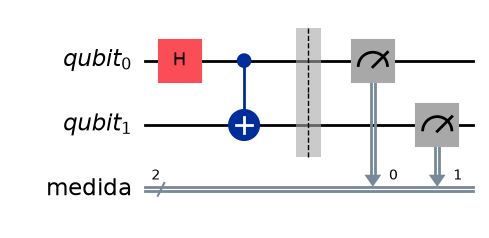

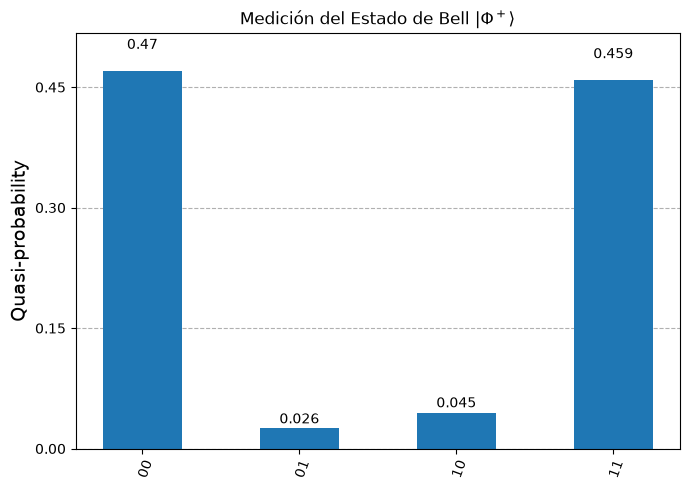

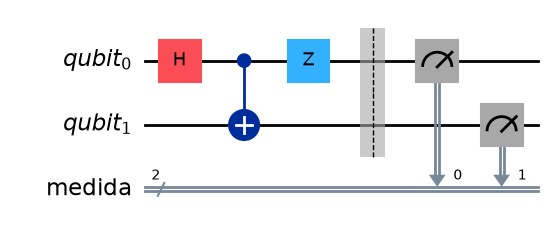

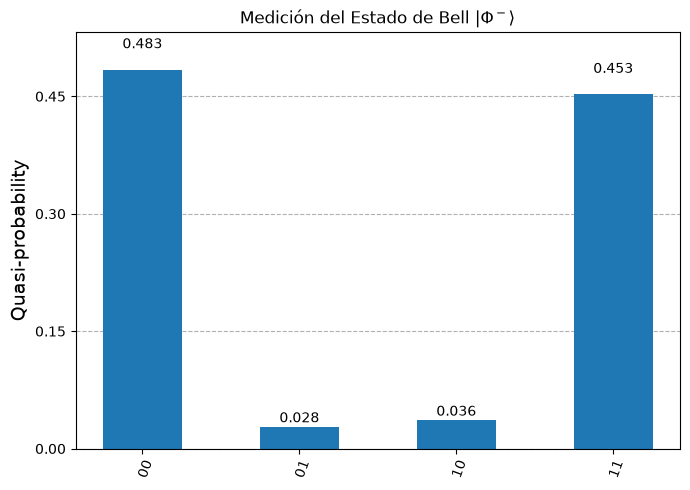

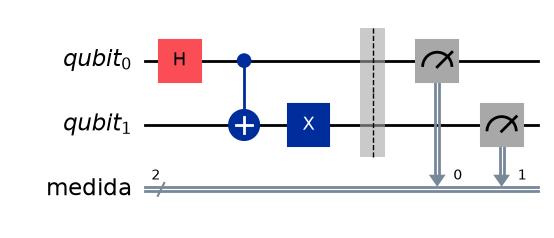

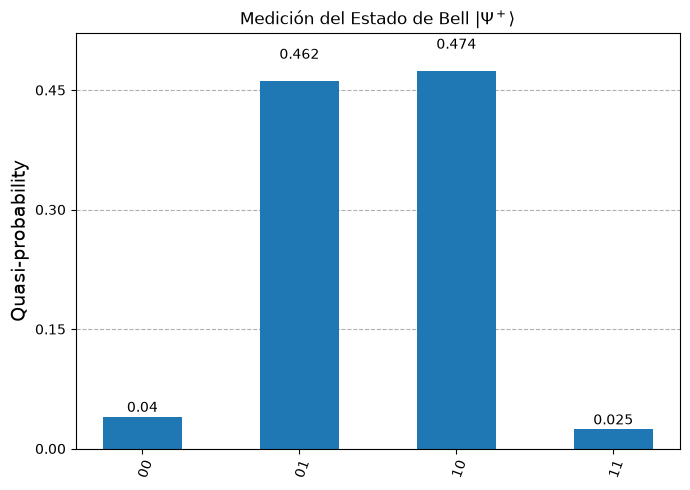

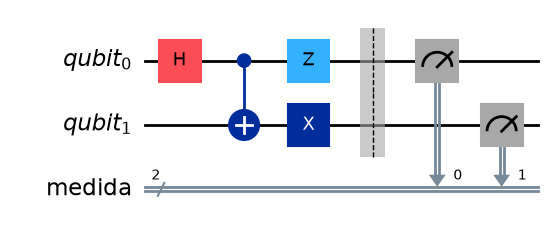

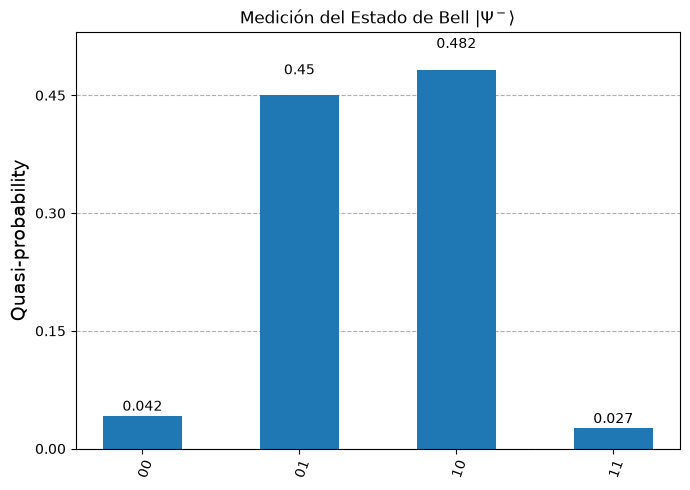

In [9]:
# Ejecución y despliegue de los resultados obtenidos para cada estado de Bell
results = {}
for label, circuit in bell_states.items():
    isa_circuit = pm.run(circuit)
    job = sampler.run([isa_circuit], shots=shots)  # Ejecución de un circuito con Sampler
    pub_result = job.result()[0]

    data_pub = pub_result.data  # Acceso a los datos del resultado para PUB 0
    counts = data_pub.medida.get_counts()  # Conteo de medidas almacenadas en el registro clásico "medida"
    results[label] = counts

    circuit.draw("mpl", style="iqp")
    plt.show()
    plot_distribution(counts, title=f'Medición del Estado de Bell $|\\{label}\\rangle$')
    plt.show()

In [10]:
from qiskit import __version__ as qiskit_version
from platform import python_version

print('Qiskit Version:', qiskit_version)
print('Python Version:', python_version())
print('2026 ©')

Qiskit Version: 2.5.2
Python Version: 3.12.11
2026 ©
